# Demand forecasting and inventory policy for a 50-SKU portfolio

*Inspired by a university Supply Chain & Operations Management assignment originally done in Excel; rebuilt independently in Python with synthetic data.*

**Question.** Does a better demand forecast actually reduce inventory cost at the same service level, and how much of the gain comes from the *forecast* versus from *how safety stock is sized*?

**Contents**
1. Synthetic data and demand patterns
2. Methods and backtest design
3. Model selection (rolling-origin backtest)
4. Held-out year 6: out-of-sample test
5. Inventory policy: ABC-XYZ, EOQ, safety stock, reorder point
6. Inventory simulation: baseline vs best model
7. Robustness across independent datasets
8. Conclusions and caveats

All numbers below are produced by this notebook from the code in `src/scm_forecast`; nothing is typed in by hand.

In [1]:
import os, warnings
warnings.filterwarnings("ignore")
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")                      # run from the repository root
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from scm_forecast.data import generate_dataset, demand_profile
from scm_forecast.pipeline import run_pipeline, summarise_simulation, SELECTION_ORIGINS, TEST_ORIGINS, HORIZON
from scm_forecast.models import METHOD_LABELS, BASELINE_METHODS
from scm_forecast.backtest import INTERMITTENT_ELIGIBLE
from scm_forecast.inventory import safety_stock_classic, safety_stock_forecast_error
from scm_forecast import plots

%matplotlib inline
pd.options.display.float_format = "{:,.3f}".format
SEED = 42

## 1. Synthetic data

The generator (`scm_forecast.data.generate_dataset`) is seeded, so the same data is rebuilt on every run. It creates **50 SKUs x 72 months**: 60 months of history (the "known" past) plus a held-out year 6 that is *only* used for out-of-sample evaluation and the inventory simulation. Five categories, seven demand patterns with fixed counts, unit costs and 12 observed monthly lead times per SKU.

In [2]:
ds = generate_dataset(SEED)
print("demand matrix:", ds.demand.shape, "| history months:", ds.n_history, "| held-out months:", ds.n_holdout)
display(ds.sku_master.groupby("pattern").agg(skus=("category", "size"), mean_monthly_demand=("base_level", "mean"),
                                             mean_unit_cost=("unit_cost", "mean"), mean_lead_time_days=("lt_mean", "mean")))
display(ds.sku_master.head(8).round(2))

demand matrix: (50, 72) | history months: 60 | held-out months: 12


,skus,mean_monthly_demand,mean_unit_cost,mean_lead_time_days
pattern,,,,
intermittent,7,2.677,41.073,17.095
seasonal,9,143.803,33.456,15.222
stable,8,193.387,12.206,14.188
trend_down,3,131.823,58.027,18.083
trend_seasonal,10,163.380,46.650,19.342
trend_up,7,192.295,30.353,18.571
volatile,6,146.057,7.378,10.639


,category,pattern,unit_cost,base_level,noise_cv,trend_per_month,lt_mean,lt_sd
sku,,,,,,,,
SKU-001,Grocery,stable,3.150,227.740,0.120,0.000,6.250,1.360
SKU-002,Grocery,seasonal,2.310,124.190,0.120,0.000,4.500,0.900
SKU-003,Grocery,seasonal,4.640,179.460,0.120,0.000,5.080,0.790
SKU-004,Grocery,volatile,3.280,274.070,0.330,0.000,3.330,1.150
SKU-005,Grocery,intermittent,2.850,2.970,NaN,0.000,8.420,1.000
SKU-006,Grocery,trend_seasonal,2.150,163.920,0.070,0.010,3.920,0.670
SKU-007,Grocery,volatile,7.910,111.940,0.400,0.000,10.170,1.700
SKU-008,Grocery,volatile,3.530,91.860,0.310,0.000,4.330,0.980


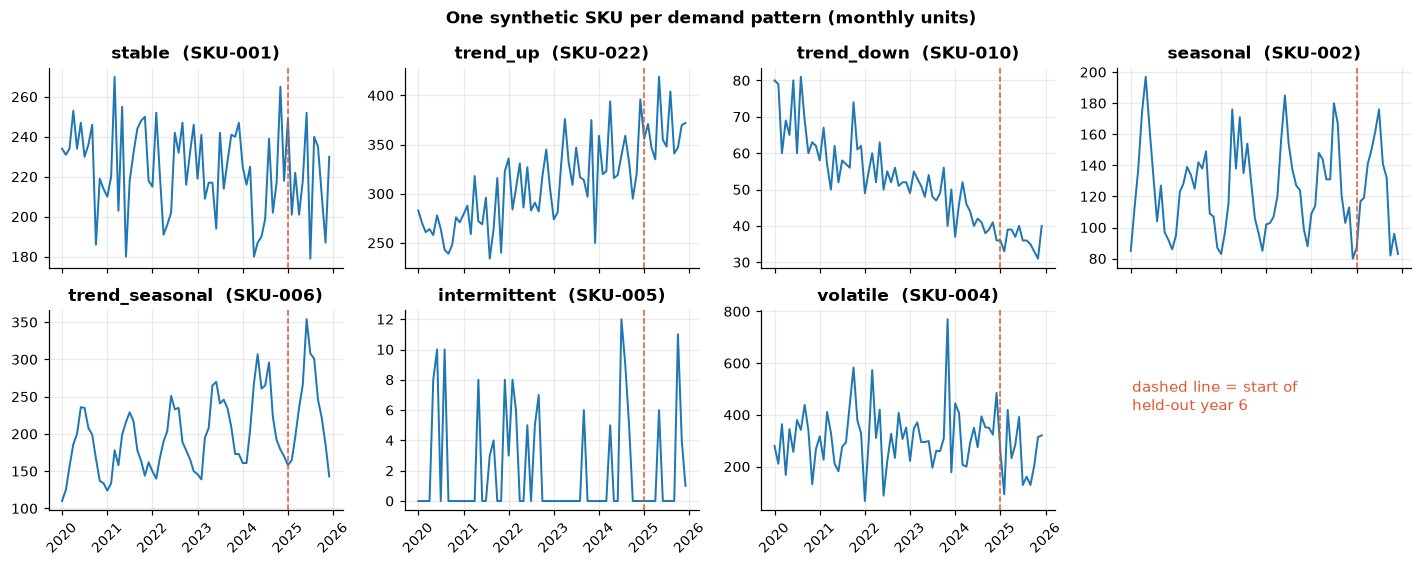

In [3]:
p, fig = plots.plot_sample_series(ds.demand, ds.sku_master)
plt.show()

sbc_class
smooth          43
intermittent     7


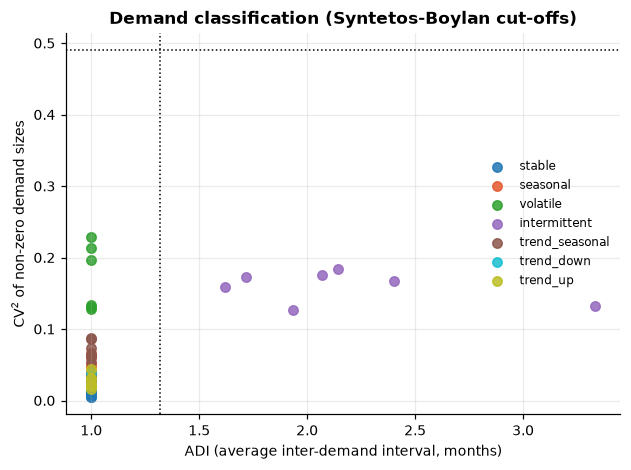

In [4]:
profile = demand_profile(ds.history)
print(profile["sbc_class"].value_counts().to_string())
p, fig = plots.plot_adi_cv2(profile, ds.sku_master)
plt.show()

## 2. Methods and backtest design

| Group | Methods |
|---|---|
| Baselines (the same family used in the Excel exercise) | Naive, Moving average (3), Weighted MA (3; weights 0.5/0.3/0.2), SES (alpha = 0.3), Holt (damped, optimised), Linear trend (OLS) |
| Advanced | Seasonal naive, Holt-Winters additive and multiplicative (statsmodels), Croston and Croston-SBA for intermittent demand, **global LightGBM** with lag/rolling features trained across all SKUs |

**Evaluation protocol (no look-ahead).**
* *Selection phase*: expanding-window **rolling origin**, 24 origins (months 36-59 of the history), horizons 1-3 months. The best method *per SKU* is the one with the lowest mean **MASE**. SKUs classified as intermittent or lumpy (ADI >= 1.32) may only pick from level methods (naive, MA, WMA, SES, Croston, SBA); trend and seasonal models are not meaningful on mostly-zero series.
* *Test phase*: the selection is frozen, then every method is evaluated on the untouched year 6 (12 rolling origins, horizons 1-3).
* Metrics: MAE, RMSE, sMAPE, MASE (scaled by the in-sample naive MAE of each SKU) and WAPE. MAPE is reported only in the spreadsheet-style comparison because it breaks down on zeros.

In [5]:
res = run_pipeline(seed=SEED, use_cache=True)   # first run takes ~1-2 min, later runs load cached CSVs
print("selection origins:", SELECTION_ORIGINS[0], "-", SELECTION_ORIGINS[-1], "| test origins:", TEST_ORIGINS[0], "-", TEST_ORIGINS[-1], "| horizon:", HORIZON)
sel_summary  = res["method_summary_selection.csv"]
test_summary = res["method_summary_test.csv"]
scores_sel   = res["backtest_selection_scores.csv"]
scores_test  = res["backtest_test_scores.csv"]
best         = res["best_method.csv"].set_index("sku")

Loading cached results from reports\results
selection origins: 36 - 59 | test origins: 60 - 71 | horizon: 3


## 3. Model selection (rolling-origin backtest)

In [6]:
t = sel_summary.copy()
t["method"] = t["method"].map(METHOD_LABELS)
t.columns = ["method", "mean MASE", "median MASE", "mean sMAPE %", "mean MAE", "mean RMSE", "mean WAPE %", "SKUs"]
display(t.set_index("method"))

,mean MASE,median MASE,mean sMAPE %,mean MAE,mean RMSE,mean WAPE %,SKUs
method,,,,,,,
Holt-Winters (mult.),0.845,0.813,30.930,21.133,26.608,29.692,50
Holt-Winters (add.),0.851,0.824,30.814,20.966,26.358,29.581,50
LightGBM (global),0.862,0.826,31.587,20.716,26.361,28.356,50
Seasonal naive,1.068,1.034,29.336,25.768,32.681,33.819,50
Linear trend (OLS),1.169,1.022,34.950,26.550,32.628,31.457,50
Holt (damped),1.187,1.015,34.613,26.963,34.137,32.114,50
Croston,1.217,1.041,34.806,27.371,34.074,32.060,50
SES (alpha=0.3),1.248,1.056,36.302,28.590,35.296,31.284,50
Weighted MA (3),1.292,1.154,34.110,29.966,36.947,32.180,50


,SKUs won
best_method,
Holt-Winters (mult.),10
Holt (damped),8
Holt-Winters (add.),7
Linear trend (OLS),6
LightGBM (global),5
Croston-SBA,4
SES (alpha=0.3),3
Moving average (3),3
Croston,3


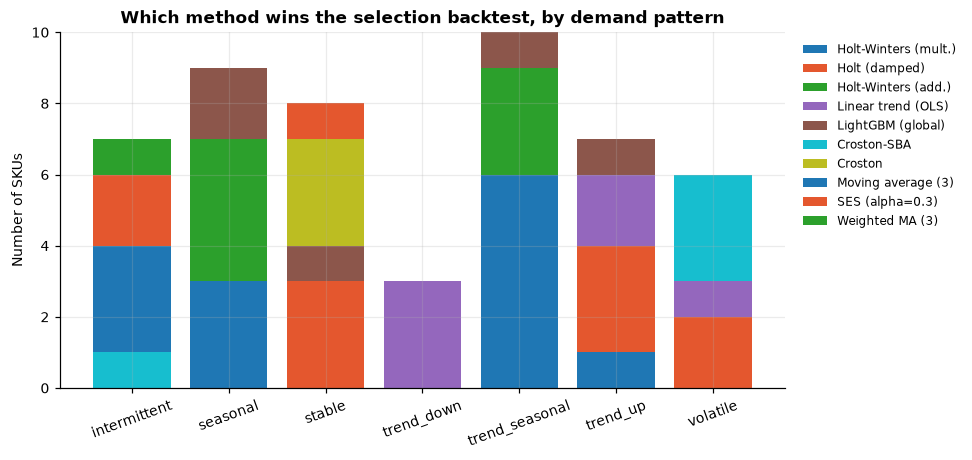

In [7]:
winners = best["best_method"].value_counts().rename("SKUs won").to_frame()
winners.index = winners.index.map(METHOD_LABELS)
display(winners)
p, fig = plots.plot_winners(best.reset_index())
plt.show()

MASE below 1 means a method beats the in-sample naive forecast. Picking the winner out of up to 12 candidates on a finite sample can be optimistic (winner's curse), so the next section re-scores everything on data that was never used for selection.

## 4. Held-out year 6

,mean MASE,median MASE,mean sMAPE %,mean MAE,mean RMSE,mean WAPE %,SKUs
method,,,,,,,
Per-SKU selection (frozen),0.757,0.724,29.248,18.425,23.008,25.805,50
Holt-Winters (mult.),0.785,0.793,30.657,19.304,24.189,27.663,50
Holt-Winters (add.),0.790,0.823,30.626,19.425,24.373,27.592,50
LightGBM (global),0.848,0.834,30.575,20.522,25.354,27.533,50
Seasonal naive,1.041,1.018,32.778,24.727,30.994,36.117,50
Linear trend (OLS),1.144,1.032,33.754,27.162,32.353,29.823,50
Holt (damped),1.174,1.060,33.481,27.596,33.574,30.363,50
Croston,1.204,1.078,34.055,28.139,33.687,30.502,50
SES (alpha=0.3),1.260,1.061,35.867,29.717,35.203,31.543,50


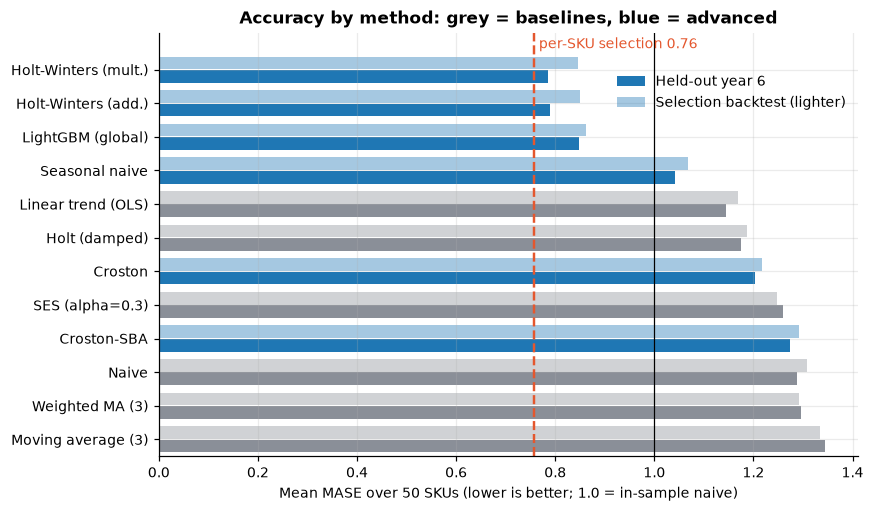

In [8]:
t = test_summary.copy()
t["method"] = t["method"].map(lambda m: METHOD_LABELS.get(m, "Per-SKU selection (frozen)"))
t.columns = ["method", "mean MASE", "median MASE", "mean sMAPE %", "mean MAE", "mean RMSE", "mean WAPE %", "SKUs"]
display(t.set_index("method"))
p, fig = plots.plot_method_mase(sel_summary, test_summary)
plt.show()

In [9]:
ts = test_summary.set_index("method")
base_best = min(BASELINE_METHODS, key=lambda m: ts.loc[m, "mean_mase"])
print(f"Best baseline on held-out data : {METHOD_LABELS[base_best]} (MASE {ts.loc[base_best,'mean_mase']:.3f})")
print(f"MA(3)                           : MASE {ts.loc['ma3','mean_mase']:.3f}")
print(f"Holt-Winters (additive)         : MASE {ts.loc['holt_winters_add','mean_mase']:.3f}")
print(f"LightGBM (global)               : MASE {ts.loc['lightgbm','mean_mase']:.3f}")
print(f"Per-SKU selection (frozen)      : MASE {ts.loc['selected','mean_mase']:.3f}")
imp_ma3 = 1 - ts.loc["selected", "mean_mase"] / ts.loc["ma3", "mean_mase"]
imp_best = 1 - ts.loc["selected", "mean_mase"] / ts.loc[base_best, "mean_mase"]
print(f"-> selection cuts MASE by {imp_ma3:.1%} vs MA(3) and {imp_best:.1%} vs the best baseline")
print(f"   RMSE: {ts.loc['ma3','mean_rmse']:.1f} (MA3) -> {ts.loc['selected','mean_rmse']:.1f} (selected) units/month per SKU")

piv = scores_test.pivot(index="sku", columns="method", values="mase")
print(f"Selected model beats MA(3) on {(piv['selected'] < piv['ma3']).mean():.0%} of SKUs in the held-out year")

ss = sel_summary.set_index("method")["mean_mase"]
print(f"\nSelected/MA(3) MASE ratio in the selection phase: {best['best_mase'].mean() / ss['ma3']:.3f}")
print(f"Selected/MA(3) MASE ratio on held-out year 6    : {ts.loc['selected','mean_mase'] / ts.loc['ma3','mean_mase']:.3f}")

Best baseline on held-out data : Linear trend (OLS) (MASE 1.144)
MA(3)                           : MASE 1.344
Holt-Winters (additive)         : MASE 0.790
LightGBM (global)               : MASE 0.848
Per-SKU selection (frozen)      : MASE 0.757
-> selection cuts MASE by 43.7% vs MA(3) and 33.8% vs the best baseline
   RMSE: 37.6 (MA3) -> 23.0 (selected) units/month per SKU
Selected model beats MA(3) on 84% of SKUs in the held-out year

Selected/MA(3) MASE ratio in the selection phase: 0.567
Selected/MA(3) MASE ratio on held-out year 6    : 0.563


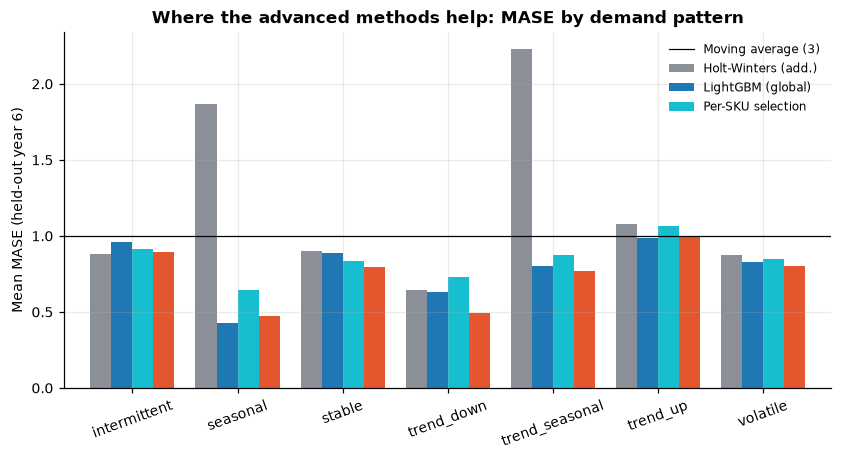

method,SKUs,MA(3),Selected,MASE reduction
pattern,,,,
intermittent,7,0.88,0.89,-1%
seasonal,9,1.87,0.48,74%
stable,8,0.90,0.79,12%
trend_down,3,0.65,0.49,24%
trend_seasonal,10,2.23,0.77,65%
trend_up,7,1.08,1.00,8%
volatile,6,0.87,0.81,8%


In [10]:
p, fig = plots.plot_pattern_improvement(scores_test, ds.sku_master)
plt.show()
bp = scores_test[scores_test.method.isin(["ma3", "selected"])].merge(ds.sku_master[["pattern"]], left_on="sku", right_index=True)
tab = bp.pivot_table(index="pattern", columns="method", values="mase").rename(columns={"ma3": "MA(3)", "selected": "Selected"})
tab["MASE reduction"] = 1 - tab["Selected"] / tab["MA(3)"]
tab.insert(0, "SKUs", ds.sku_master["pattern"].value_counts())
display(tab.style.format({"MA(3)": "{:.2f}", "Selected": "{:.2f}", "MASE reduction": "{:.0%}"}))

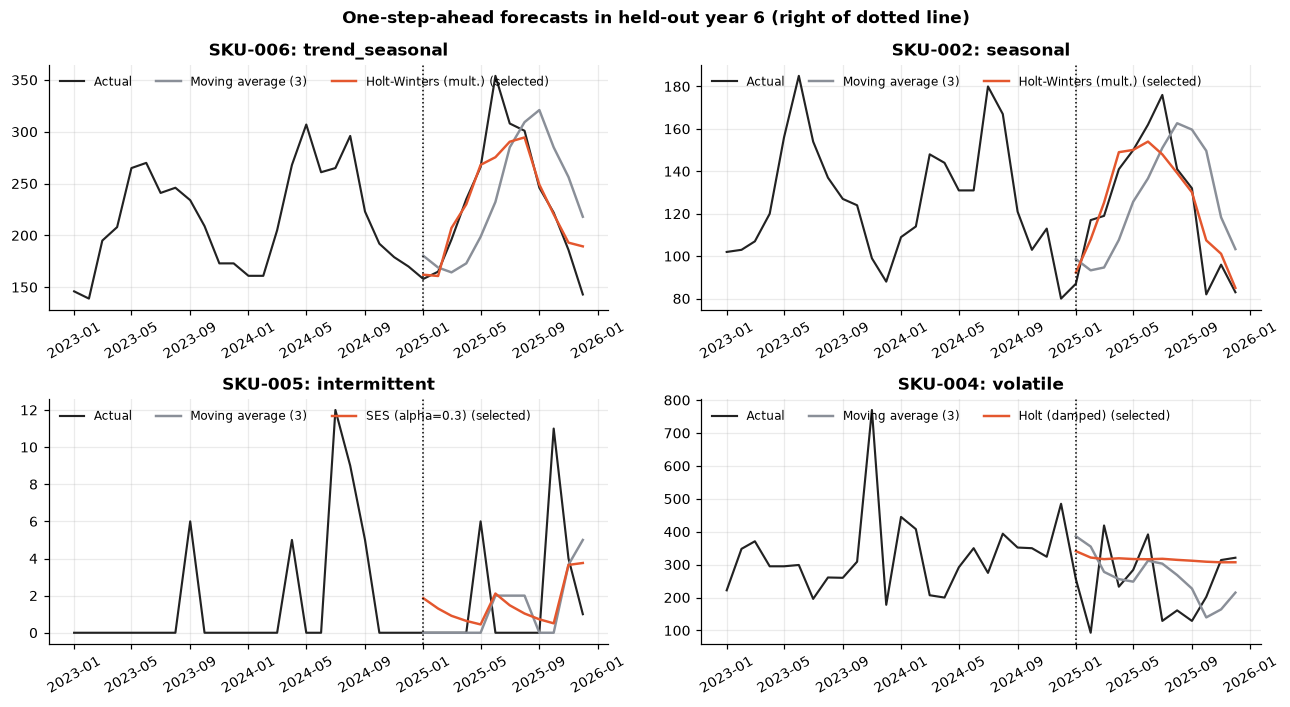

In [11]:
p, fig = plots.plot_forecast_examples(ds.demand, res["forecasts_test.csv"], best, ds.sku_master)
plt.show()

### Spreadsheet-style comparison

The Excel exercise produced a **single 12-month-ahead forecast** from the end of year 5 and scored it with MAD, MAPE and MSE. The same protocol on the synthetic data (one origin, horizon 12) is shown below for the three spreadsheet methods and the strongest advanced ones. Single-origin, long-horizon scores are noisier than the rolling-origin results above; MAPE skips zero-demand months.

In [12]:
x = res["excel_style_year6.csv"]
x = x.merge(best[["best_method"]], left_on="sku", right_index=True)
sel_rows = x[x["method"] == x["best_method"]].assign(method="selected")
x = pd.concat([x, sel_rows])
agg = x.groupby("method").agg(MAD=("mad", "mean"), MAPE_pct=("mape", "mean"), MSE=("mse", "mean"),
                              MASE=("mase", "mean"), annual_fc=("annual_forecast", "sum"), annual_actual=("annual_actual", "sum"))
agg["annual bias %"] = (agg["annual_fc"] / agg["annual_actual"] - 1) * 100
show = ["ma3", "ses", "linear_trend", "holt_winters_add", "lightgbm", "selected"]
agg = agg.loc[show, ["MAD", "MAPE_pct", "MSE", "MASE", "annual bias %"]]
agg.index = [METHOD_LABELS.get(i, "Per-SKU selection") for i in agg.index]
display(agg)

,MAD,MAPE_pct,MSE,MASE,annual bias %
Moving average (3),31.743,29.046,"2,681.468",1.306,2.889
SES (alpha=0.3),29.039,26.936,"2,221.704",1.198,1.516
Linear trend (OLS),26.623,25.694,"1,796.904",1.100,2.788
Holt-Winters (add.),19.668,21.888,"1,298.415",0.791,1.651
LightGBM (global),21.749,22.633,"1,548.766",0.890,0.965
Per-SKU selection,18.806,20.469,"1,165.559",0.758,0.727


## 5. Inventory policy

For each SKU: **ABC** by annual consumption value (last 12 months x unit cost; A = top 80 %, B = next 15 %), **XYZ** by coefficient of variation of monthly demand over the last 24 months (X < 0.30, Y < 0.60, Z otherwise). Target cycle service levels follow ABC (A 98 %, B 95 %, C 90 %). Ordering cost is 40 per order, holding cost 25 % of unit cost per year, and a lost sale costs 50 % of unit cost (all assumptions).

* EOQ = sqrt(2 D S / H)
* Classic safety stock (textbook): SS = z * sigma_d * sqrt(LT), with sigma_d the standard deviation of *demand*
* Forecast-error safety stock: SS = z * sqrt( LT/30 * sigma_e^2 + (d * sigma_LT)^2 ), with sigma_e the RMSE of one-step *forecast errors* and sigma_LT the lead-time standard deviation
* ROP = d * LT + SS

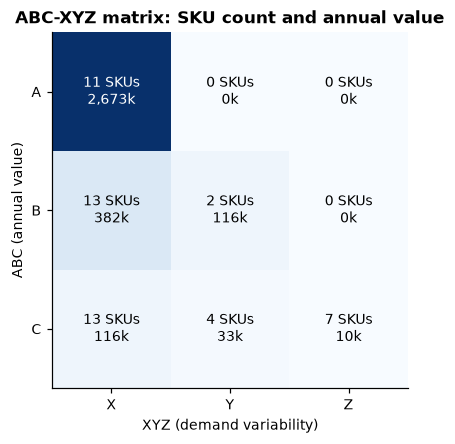

,skus,annual_value,service_level,value_share
abc,,,,
A,11,"2,672,635",98%,80.3%
B,15,"497,586",95%,14.9%
C,24,"158,741",90%,4.8%


,category,pattern,abc_xyz,annual_demand,cv,service_level,lt_mean,eoq
sku,,,,,,,,
SKU-001,Grocery,stable,CX,2563,0.100,0.900,6.250,510.260
SKU-002,Grocery,seasonal,CX,1541,0.220,0.900,4.500,462.030
SKU-003,Grocery,seasonal,CX,2133,0.170,0.900,5.080,383.540
SKU-004,Grocery,volatile,CY,4082,0.370,0.900,3.330,631.070
SKU-005,Grocery,intermittent,CZ,31,2.160,0.900,8.420,59.000
SKU-006,Grocery,trend_seasonal,CX,2688,0.220,0.900,3.920,632.510
SKU-007,Grocery,volatile,CY,1444,0.540,0.900,10.170,241.700
SKU-008,Grocery,volatile,CY,859,0.480,0.900,4.330,279.050


In [13]:
inputs = res["sku_policy_inputs.csv"].set_index("sku")
p, fig = plots.plot_abc_xyz(inputs)
plt.show()
display(inputs.groupby("abc").agg(skus=("abc", "size"), annual_value=("annual_value", "sum"), service_level=("service_level", "first")).assign(
    value_share=lambda d: d["annual_value"] / d["annual_value"].sum()).style.format({"annual_value": "{:,.0f}", "value_share": "{:.1%}", "service_level": "{:.0%}"}))
display(inputs[["category", "pattern", "abc_xyz", "annual_demand", "cv", "service_level", "lt_mean", "eoq"]].head(8).round(2))

### How much safety stock does a better forecast save?

Using the selection-phase one-step errors, compare the buffer a planner would set for the same service targets with (A) the textbook demand standard deviation, (B) MA(3) forecast error, (C) the selected model's forecast error.

In [14]:
fs = res["forecasts_selection.csv"]
h1 = fs[fs.h == 1].assign(e2=lambda d: (d.y_pred - d.y_true) ** 2)
rmse_by = h1.groupby(["method", "sku"])["e2"].mean().pow(0.5)
sigma_ma3 = rmse_by["ma3"]
sigma_best = pd.Series({s: rmse_by[(best.at[s, "best_method"], s)] for s in best.index})
sigma_d = ds.history.iloc[:, -12:].std(axis=1, ddof=1)
z, lt, ltsd = inputs["z"], inputs["lt_mean"], inputs["lt_sd"]
d_daily = ds.history.iloc[:, -12:].mean(axis=1) / 30
cmp = pd.DataFrame({
    "A classic (sigma_d)": [safety_stock_classic(z[s], sigma_d[s], lt[s]) for s in inputs.index],
    "B MA(3) error":        [safety_stock_forecast_error(z[s], sigma_ma3[s], lt[s], d_daily[s], ltsd[s]) for s in inputs.index],
    "C best-model error":   [safety_stock_forecast_error(z[s], sigma_best[s], lt[s], d_daily[s], ltsd[s]) for s in inputs.index],
}, index=inputs.index)
val = cmp.mul(inputs["unit_cost"], axis=0).sum()
out = pd.DataFrame({"safety stock (units)": cmp.sum(), "safety stock value": val})
out["vs B"] = out["safety stock value"] / out.loc["B MA(3) error", "safety stock value"] - 1
display(out.style.format({"safety stock (units)": "{:,.0f}", "safety stock value": "{:,.0f}", "vs B": "{:+.1%}"}))

,safety stock (units),safety stock value,vs B
A classic (sigma_d),"1,911","89,823",-36.8%
B MA(3) error,"2,767","142,017",+0.0%
C best-model error,"2,346","119,894",-15.6%


## 6. Inventory simulation: baseline vs best model

A **daily (s, Q) simulation** of year 6 for each SKU: continuous review, order Q (EOQ from the month's forecast) whenever inventory position <= ROP, lost sales when stocked out, random lead times drawn from each SKU's observed mean/std. Monthly actual demand is spread across 30 days with a seeded multinomial draw. Parameters (ROP, Q) are refreshed every month from that month's one-step-ahead forecast. All three policies see **identical demand and lead-time draws**, so differences come from the policy only.

* **A. Classic**: MA(3) forecast + safety stock from demand standard deviation (the textbook approach)
* **B. MA(3) + forecast-error SS**: isolates the effect of sizing the buffer on forecast error
* **C. Best model + forecast-error SS**: per-SKU selected model (frozen before year 6)

,orders,ordering_cost,holding_cost,shortage_cost,total_cost,lost_units,fill_rate,avg_inventory_value
A. Classic MA(3) + demand-sd SS,505,"20,200","49,947","46,056","116,203","1,462",98.56%,"199,786"
B. MA(3) + forecast-error SS,516,"20,640","62,731","6,179","89,550",337,99.67%,"250,923"
C. Best model + forecast-error SS,508,"20,320","55,907","1,389","77,616",163,99.84%,"223,627"


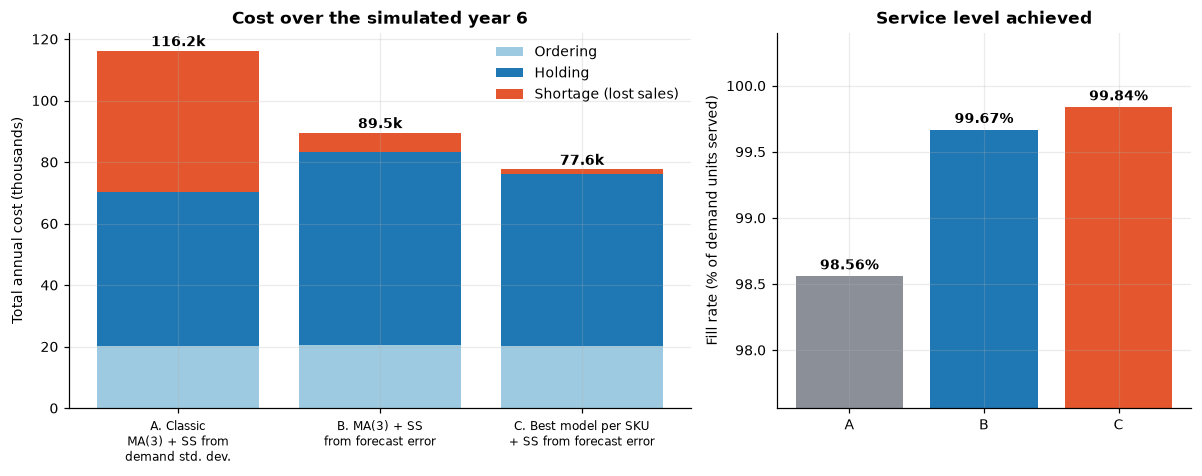

In [15]:
sim = res["simulation_sku.csv"]
sums = res["simulation_summary.csv"].set_index("policy").loc[["classic_ma3", "ma3_errorSS", "best_errorSS"]]
disp = sums[["orders", "ordering_cost", "holding_cost", "shortage_cost", "total_cost", "lost_units", "fill_rate", "avg_inventory_value"]].copy()
disp.index = ["A. Classic MA(3) + demand-sd SS", "B. MA(3) + forecast-error SS", "C. Best model + forecast-error SS"]
display(disp.style.format({"ordering_cost": "{:,.0f}", "holding_cost": "{:,.0f}", "shortage_cost": "{:,.0f}", "total_cost": "{:,.0f}",
                           "lost_units": "{:,.0f}", "fill_rate": "{:.2%}", "avg_inventory_value": "{:,.0f}"}))
p, fig = plots.plot_sim_cost(res["simulation_summary.csv"])
plt.show()

In [16]:
a, b, c = (sums.loc[k] for k in ["classic_ma3", "ma3_errorSS", "best_errorSS"])
print(f"C vs A : total cost {c.total_cost/a.total_cost-1:+.1%}, fill rate {a.fill_rate:.2%} -> {c.fill_rate:.2%}, lost units {a.lost_units:,.0f} -> {c.lost_units:,.0f}, avg inventory value {c.avg_inventory_value/a.avg_inventory_value-1:+.1%}")
print(f"C vs B : total cost {c.total_cost/b.total_cost-1:+.1%}, fill rate {b.fill_rate:.2%} -> {c.fill_rate:.2%}, avg inventory value {c.avg_inventory_value/b.avg_inventory_value-1:+.1%}")
print(f"B vs A : total cost {b.total_cost/a.total_cost-1:+.1%}  (effect of sizing safety stock on forecast error alone)")
per = sim.pivot(index="sku", columns="policy", values="total_cost")
print(f"C is cheaper than A for {(per.best_errorSS < per.classic_ma3).mean():.0%} of SKUs and cheaper than B for {(per.best_errorSS < per.ma3_errorSS).mean():.0%}")

C vs A : total cost -33.2%, fill rate 98.56% -> 99.84%, lost units 1,462 -> 163, avg inventory value +11.9%
C vs B : total cost -13.3%, fill rate 99.67% -> 99.84%, avg inventory value -10.9%
B vs A : total cost -22.9%  (effect of sizing safety stock on forecast error alone)
C is cheaper than A for 54% of SKUs and cheaper than B for 72%


The saving is **not uniform**. The table splits total cost by demand pattern: where demand is stable or declining a simple moving average plus a demand-based buffer is already adequate, and the gain comes from the seasonal and trending SKUs that a 3-month average chases with a lag.

,A cost,B cost,C cost,C vs A,fill A,fill C
pattern,,,,,,
intermittent,"1,569","1,617","1,366",-12.9%,99.54%,100.00%
seasonal,"20,991","20,148","15,717",-25.1%,99.12%,99.84%
stable,"6,797","6,904","6,945",+2.2%,99.77%,99.95%
trend_down,"4,886","5,196","5,034",+3.0%,99.52%,100.00%
trend_seasonal,"42,846","32,870","26,516",-38.1%,98.62%,99.90%
trend_up,"34,278","18,129","17,631",-48.6%,96.94%,99.80%
volatile,"4,836","4,686","4,406",-8.9%,99.15%,99.53%


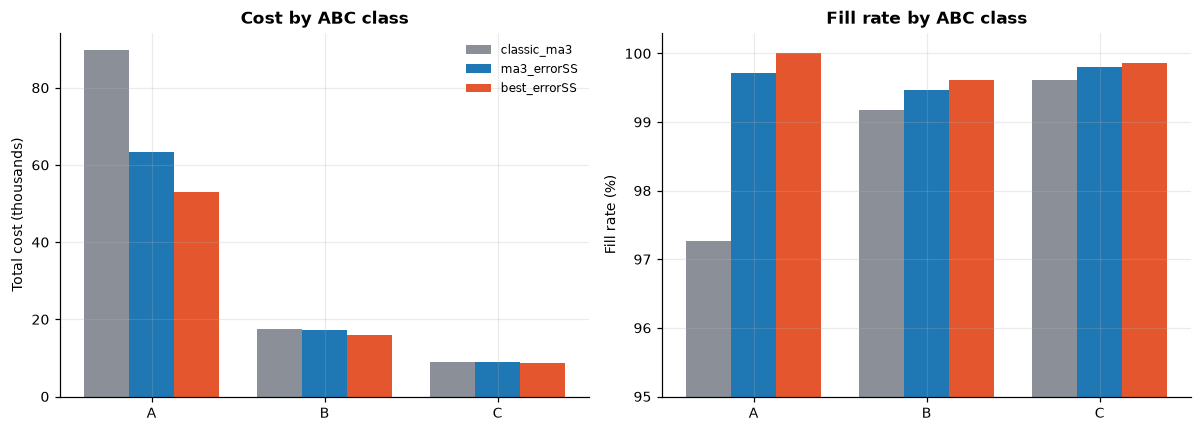

In [17]:
sp = sim.merge(ds.sku_master[["pattern"]], left_on="sku", right_index=True)
bp = sp.groupby(["pattern", "policy"]).agg(cost=("total_cost", "sum"), lost=("lost_units", "sum"), dem=("demand_units", "sum")).reset_index()
bp["fill"] = 1 - bp["lost"] / bp["dem"]
tab = bp.pivot(index="pattern", columns="policy", values="cost")[["classic_ma3", "ma3_errorSS", "best_errorSS"]]
tab.columns = ["A cost", "B cost", "C cost"]
tab["C vs A"] = tab["C cost"] / tab["A cost"] - 1
tab["fill A"] = bp.pivot(index="pattern", columns="policy", values="fill")["classic_ma3"]
tab["fill C"] = bp.pivot(index="pattern", columns="policy", values="fill")["best_errorSS"]
display(tab.style.format({"A cost": "{:,.0f}", "B cost": "{:,.0f}", "C cost": "{:,.0f}", "C vs A": "{:+.1%}", "fill A": "{:.2%}", "fill C": "{:.2%}"}))
p, fig = plots.plot_sim_by_class(sim)
plt.show()
bc = summarise_simulation(sim, ["abc"]).pivot(index="abc", columns="policy", values=["total_cost", "fill_rate"])
display(bc.style.format("{:,.3f}"))

### Sensitivity to the lost-sale penalty

The lost-sale cost (50 % of unit cost) is an assumption, and the cost ranking depends on it: policy A holds less stock but loses more sales. Because the policy parameters do not depend on the penalty, the simulation can simply be re-costed.

,A classic,B MA(3)+error SS,C best+error SS
lost sale cost / unit cost,,,
0.000000,"70,147","83,371","76,227"
0.050000,"74,752","83,989","76,366"
0.100000,"79,358","84,607","76,504"
0.250000,"93,175","86,460","76,921"
0.500000,"116,203","89,550","77,616"
1.000000,"162,258","95,728","79,004"


Policy C becomes cheaper than policy A once a lost sale costs more than about 7% of the unit cost.


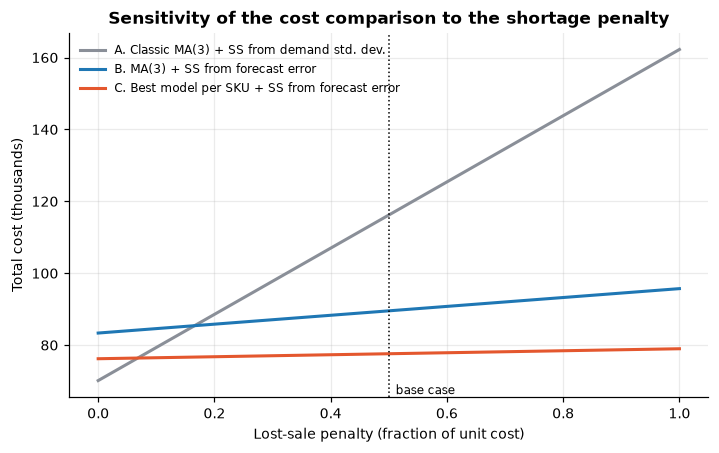

In [18]:
ratios = [0, 0.05, 0.10, 0.25, 0.50, 1.0]
sens = pd.DataFrame({r: plots.recost(sim, r) for r in ratios}).T.loc[:, ["classic_ma3", "ma3_errorSS", "best_errorSS"]]
sens.columns = ["A classic", "B MA(3)+error SS", "C best+error SS"]
sens.index.name = "lost sale cost / unit cost"
display(sens.style.format("{:,.0f}"))
rs = np.linspace(0, 1, 2001)
be = next(r for r in rs if plots.recost(sim, r)["best_errorSS"] <= plots.recost(sim, r)["classic_ma3"])
print(f"Policy C becomes cheaper than policy A once a lost sale costs more than about {be:.0%} of the unit cost.")
p, fig = plots.plot_shortage_sensitivity(sim)
plt.show()

## 7. Robustness across independent datasets

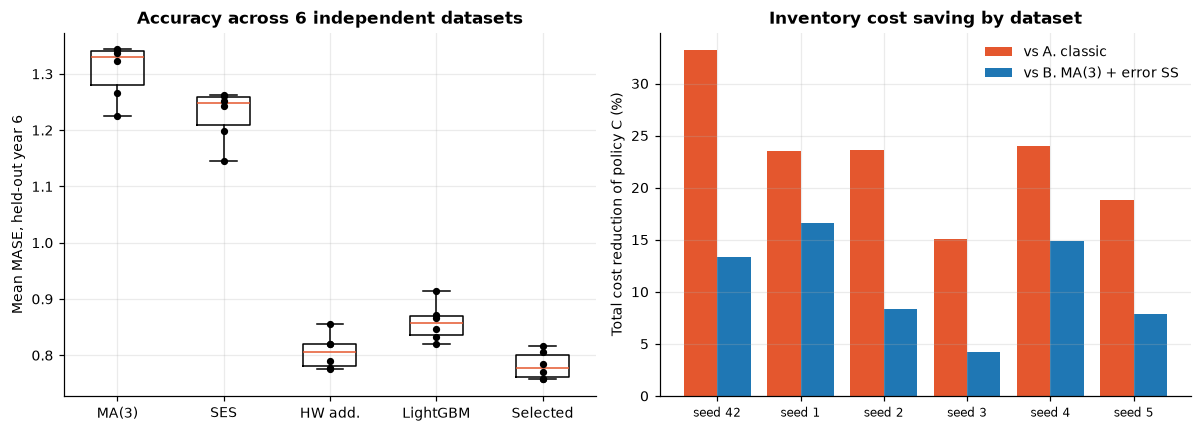

,seed,MASE MA(3),MASE selected,cost A,cost B,cost C,fill A,fill C
0,42,1.344,0.757,"116,203","89,550","77,616",98.56%,99.84%
1,1,1.266,0.757,"120,207","110,225","91,925",99.04%,99.85%
2,2,1.323,0.785,"114,429","95,307","87,362",98.00%,99.46%
3,3,1.337,0.817,"75,118","66,600","63,773",99.02%,99.82%
4,4,1.226,0.771,"110,985","99,120","84,388",99.13%,99.77%
5,5,1.342,0.807,"93,467","82,297","75,842",99.12%,99.86%


Cost reduction C vs A: mean 23.1% (min 15.1%, max 33.2%)
Cost reduction C vs B: mean 10.9% (min 4.2%, max 16.6%)
MASE reduction selected vs MA(3): mean 40.1%
Seed 42 (the one used above) gives the largest cost reduction vs A: True


In [19]:
from pathlib import Path
rp = Path("reports/results/robustness_seeds.csv")
if rp.exists():
    rob = pd.read_csv(rp)
    p, fig = plots.plot_robustness(rob)
    plt.show()
    r = pd.DataFrame({
        "seed": rob.seed,
        "MASE MA(3)": rob.mase_ma3, "MASE selected": rob.mase_selected,
        "cost A": rob.cost_classic_ma3, "cost B": rob.cost_ma3_errorSS, "cost C": rob.cost_best_errorSS,
        "fill A": rob.fill_classic_ma3, "fill C": rob.fill_best_errorSS,
    })
    display(r.style.format({"cost A": "{:,.0f}", "cost B": "{:,.0f}", "cost C": "{:,.0f}", "fill A": "{:.2%}", "fill C": "{:.2%}", "MASE MA(3)": "{:.3f}", "MASE selected": "{:.3f}"}))
    ca = 1 - rob.cost_best_errorSS / rob.cost_classic_ma3
    cb = 1 - rob.cost_best_errorSS / rob.cost_ma3_errorSS
    print(f"Cost reduction C vs A: mean {ca.mean():.1%} (min {ca.min():.1%}, max {ca.max():.1%})")
    print(f"Cost reduction C vs B: mean {cb.mean():.1%} (min {cb.min():.1%}, max {cb.max():.1%})")
    print(f"MASE reduction selected vs MA(3): mean {(1 - rob.mase_selected / rob.mase_ma3).mean():.1%}")
    print(f"Seed {SEED} (the one used above) gives the largest cost reduction vs A: {ca[rob.seed == SEED].iloc[0] == ca.max()}")
else:
    print("Run `python scripts/robustness.py` to create reports/results/robustness_seeds.csv")

## 8. Conclusions and caveats

**What the evidence says**
* Models that capture seasonality and trend (Holt-Winters, global LightGBM, and the per-SKU selection that mostly picks them) are far more accurate than the spreadsheet-style moving averages on the seasonal and trend-seasonal SKUs. On stable, volatile and intermittent SKUs every method lands within a narrow band and a simple average or Croston is as good as anything.
* Per-SKU selection by rolling-origin backtest generalised: its advantage over MA(3) on the held-out year is about the same as in the selection phase (see the ratios in section 4). For the intermittent SKUs the selection gives no gain over Croston or SES.
* In the simulation there are two separable effects: sizing safety stock on *forecast error* instead of raw demand spread (B vs A), and the better forecast itself (C vs B), which lowers the error and therefore the buffer needed for the same service target.
* The forecast-error buffers are *larger* than the textbook demand-based ones, because a 3-month average lags seasonal and trending demand; that bigger buffer is what removes most lost sales (policy A looks leaner but is under-protected). A better model then shrinks the error-based buffer (see the safety-stock table in section 5).
* The cost win is concentrated in seasonal and trending SKUs and comes mostly from fewer lost sales. It reverses if lost sales are cheap (see the sensitivity table).

**Caveats**
* The data are synthetic: patterns are cleaner than real demand and there are no promotions, stock-outs in history or supplier disruptions. Absolute numbers will not transfer; the *method* does.
* Costs (order 40, holding 25 % per year, lost sale 50 % of unit cost) and service targets are assumptions. Re-run with your own figures.
* Monthly demand was disaggregated to days with a random split; real intra-month demand has structure.
* The z-score safety stock assumes roughly normal errors, which is poor for very low-volume intermittent SKUs.
* Lost-sales, single-echelon, no capacity or minimum-order constraints; only one simulated year per dataset.
* The restriction of intermittent SKUs to level methods was added after a first run in which the unrestricted selection picked seasonal methods for mostly-zero series (see README).